In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from scipy import stats

In [2]:
data = {

'Student': ['A','B','C','D','E','F','G','H','I','J',

'K','L','M','N','O','P','Q','R','S','T'],


'Marks': [45, 50, 52, 48, 55, 60, 58, 62, 65, 59,

61, 57, 63, 56, 54, 51, 49, 95, 100, 5]

}

df = pd.DataFrame(data)

print(df)

   Student  Marks
0        A     45
1        B     50
2        C     52
3        D     48
4        E     55
5        F     60
6        G     58
7        H     62
8        I     65
9        J     59
10       K     61
11       L     57
12       M     63
13       N     56
14       O     54
15       P     51
16       Q     49
17       R     95
18       S    100
19       T      5


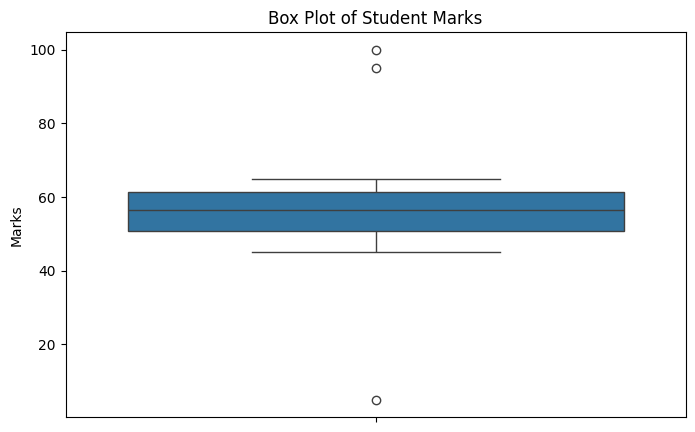

In [3]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Marks'])

plt.title("Box Plot of Student Marks")

plt.ylabel("Marks")

plt.show()

In [4]:
Q1 = df['Marks'].quantile(0.25)

Q3 = df['Marks'].quantile(0.75)

print("Q1 =", Q1)

print("Q3 =", Q3)

Q1 = 50.75
Q3 = 61.25


In [5]:
IQR = Q3 - Q1

print("IQR =", IQR)

IQR = 10.5


In [6]:
lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Lower Limit =", lower_limit)

print("Upper Limit =", upper_limit)

Lower Limit = 35.0
Upper Limit = 77.0


In [7]:
outliers_iqr = df[

(df['Marks'] < lower_limit) |

(df['Marks'] > upper_limit)

]

print("Outliers detected using IQR:")

print(outliers_iqr)

Outliers detected using IQR:
   Student  Marks
17       R     95
18       S    100
19       T      5


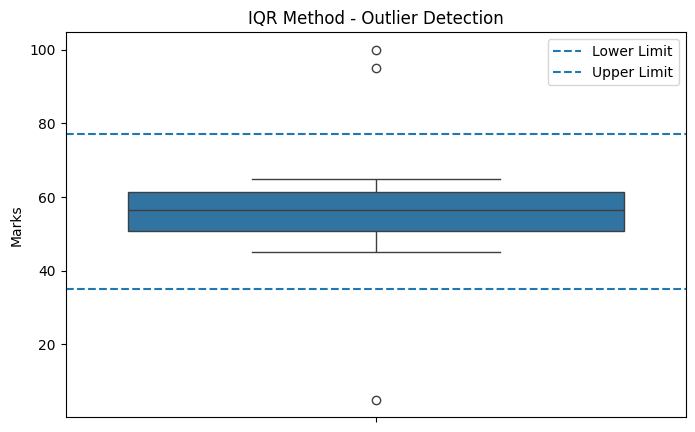

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(y=df['Marks'])

plt.axhline(lower_limit, linestyle='--', label='Lower Limit')

plt.axhline(upper_limit, linestyle='--', label='Upper Limit')

plt.title("IQR Method - Outlier Detection")

plt.legend()

plt.show()

In [9]:
df['Marks_IQR_Capped'] = df['Marks'].clip(

lower=lower_limit,

upper=upper_limit

)

print(df[['Marks', 'Marks_IQR_Capped']])

    Marks  Marks_IQR_Capped
0      45                45
1      50                50
2      52                52
3      48                48
4      55                55
5      60                60
6      58                58
7      62                62
8      65                65
9      59                59
10     61                61
11     57                57
12     63                63
13     56                56
14     54                54
15     51                51
16     49                49
17     95                77
18    100                77
19      5                35


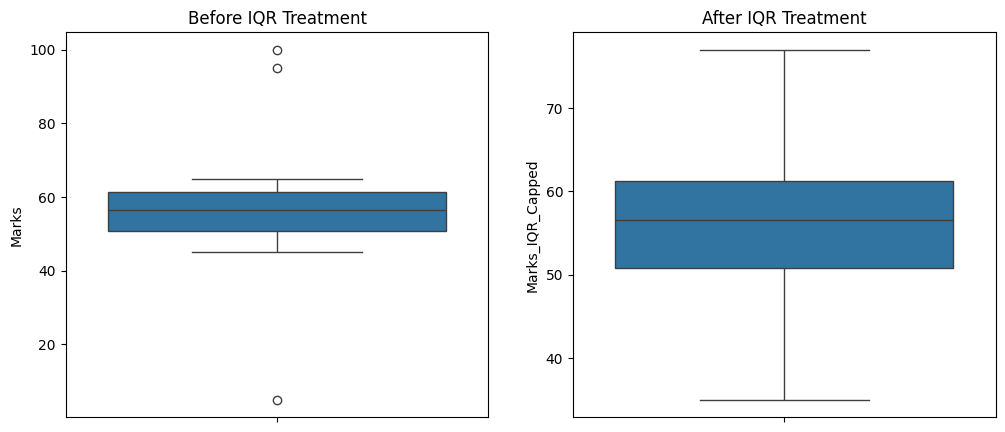

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df['Marks'], ax=axes[0])

axes[0].set_title("Before IQR Treatment")

sns.boxplot(y=df['Marks_IQR_Capped'], ax=axes[1])

axes[1].set_title("After IQR Treatment")

plt.show()

In [11]:
df['Z_score'] = stats.zscore(df['Marks'])

print(df[['Marks', 'Z_score']])

    Marks   Z_score
0      45 -0.676200
1      50 -0.400200
2      52 -0.289800
3      48 -0.510600
4      55 -0.124200
5      60  0.151800
6      58  0.041400
7      62  0.262200
8      65  0.427800
9      59  0.096600
10     61  0.207000
11     57 -0.013800
12     63  0.317400
13     56 -0.069000
14     54 -0.179400
15     51 -0.345000
16     49 -0.455400
17     95  2.083800
18    100  2.359799
19      5 -2.884199


In [12]:
z_outliers = df[abs(df['Z_score']) > 2]

print("Outliers detected using Z-score:")

print(z_outliers)


Outliers detected using Z-score:
   Student  Marks  Marks_IQR_Capped   Z_score
17       R     95                77  2.083800
18       S    100                77  2.359799
19       T      5                35 -2.884199


In [13]:
df['Z_Outlier'] = abs(df['Z_score']) > 2

print(df[['Marks', 'Z_score', 'Z_Outlier']])

    Marks   Z_score  Z_Outlier
0      45 -0.676200      False
1      50 -0.400200      False
2      52 -0.289800      False
3      48 -0.510600      False
4      55 -0.124200      False
5      60  0.151800      False
6      58  0.041400      False
7      62  0.262200      False
8      65  0.427800      False
9      59  0.096600      False
10     61  0.207000      False
11     57 -0.013800      False
12     63  0.317400      False
13     56 -0.069000      False
14     54 -0.179400      False
15     51 -0.345000      False
16     49 -0.455400      False
17     95  2.083800       True
18    100  2.359799       True
19      5 -2.884199       True


In [14]:
mean = df['Marks'].mean()

std = df['Marks'].std()

lower_z_limit = mean - 2 * std

upper_z_limit = mean + 2 * std

print("Lower Z-score limit =", lower_z_limit)

print("Upper Z-score limit =", upper_z_limit)

Lower Z-score limit = 20.076863123175116
Upper Z-score limit = 94.42313687682488


In [15]:
df['Marks_Z_Capped'] = df['Marks'].clip(

lower=lower_z_limit,

upper=upper_z_limit

)

print(df[['Marks', 'Marks_Z_Capped']])

    Marks  Marks_Z_Capped
0      45       45.000000
1      50       50.000000
2      52       52.000000
3      48       48.000000
4      55       55.000000
5      60       60.000000
6      58       58.000000
7      62       62.000000
8      65       65.000000
9      59       59.000000
10     61       61.000000
11     57       57.000000
12     63       63.000000
13     56       56.000000
14     54       54.000000
15     51       51.000000
16     49       49.000000
17     95       94.423137
18    100       94.423137
19      5       20.076863


In [16]:
print(df[['Marks',

'Marks_IQR_Capped',

'Marks_Z_Capped']])


    Marks  Marks_IQR_Capped  Marks_Z_Capped
0      45                45       45.000000
1      50                50       50.000000
2      52                52       52.000000
3      48                48       48.000000
4      55                55       55.000000
5      60                60       60.000000
6      58                58       58.000000
7      62                62       62.000000
8      65                65       65.000000
9      59                59       59.000000
10     61                61       61.000000
11     57                57       57.000000
12     63                63       63.000000
13     56                56       56.000000
14     54                54       54.000000
15     51                51       51.000000
16     49                49       49.000000
17     95                77       94.423137
18    100                77       94.423137
19      5                35       20.076863


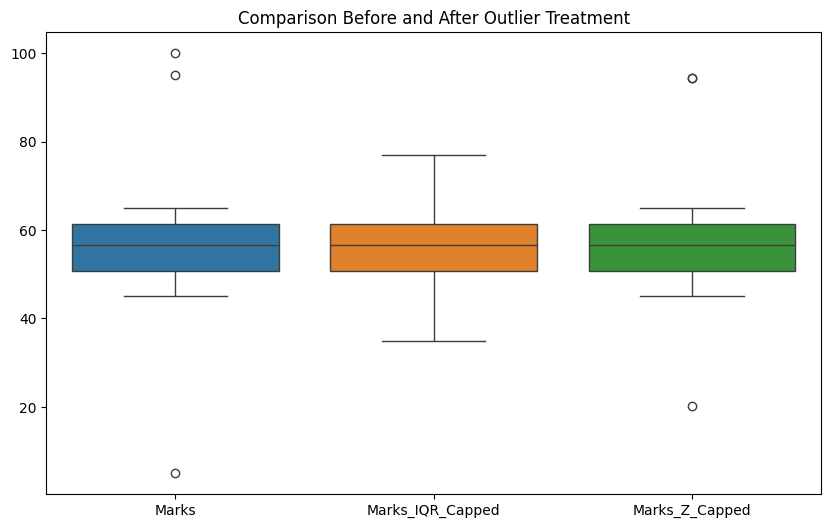

In [17]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df[

['Marks', 'Marks_IQR_Capped', 'Marks_Z_Capped']

])

plt.title("Comparison Before and After Outlier Treatment")

plt.show()